# Test finite-shot IPR noise

This notebook tests finite-shot noisy IPR feature generation and noisy IPR-kernel SVM experiments.


In [1]:
from pathlib import Path
import importlib
import sys

import numpy as np
import pandas as pd

cwd = Path.cwd()
script_dir = cwd if (cwd / "finite_shot_noise.py").exists() else cwd / "scripts"
if str(script_dir) not in sys.path:
    sys.path.insert(0, str(script_dir))

import finite_shot_noise as noise_tools
import run_iprkernel_svm as svm_runner
importlib.reload(noise_tools)
importlib.reload(svm_runner)

from finite_shot_noise import compute_ipr_gram_from_features, make_finite_shot_noisy_ipr_dataset
from run_iprkernel_svm import run_noisy_iprkernel_svm_experiment, run_noisy_iprkernel_svm_ns_sweep

# print("Using noise tools:", noise_tools.__file__)
# print("Using SVM runner:", svm_runner.__file__)
%matplotlib inline

## Finite-shot noise process

1. Load processed raw IPR features for TFIM 1D. The noisy helper currently supports `dataset="tfim1d"` only.
2. Build one feature vector per parameter point, for example `[IPR X, IPR Z]`.
3. Add independent Gaussian noise directly to the raw IPR values, not to the `log10` values.
4. The noise scale is `sigma = 1 / sqrt(N_s)`.
5. By default, noisy IPR values are clipped to `[1 / N_s, 1]`.
6. Build the noisy IPR Gram matrix from the noisy raw features.
7. Run the precomputed-kernel SVM and report global/local balanced accuracy only.

In the noisy SVM experiment, each noise seed creates a different noisy kernel. The SVM train/test partitions vary across `split_id`, but the same split sequence is reused across noise seeds for a fixed `rng_seed`.


In [2]:
L_VALUES_TFIM1D = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]


def noisy_svm_score_table(results):
    """Return a compact noisy-SVM balanced-accuracy summary table."""
    return pd.DataFrame(
        {
            "L": results["L"],
            "global_bal_acc_mean": results["global_bal_acc_mean"],
            "global_bal_acc_std_over_noise_seed": results["global_bal_acc_std_over_noise_seed"],
            "local_bal_acc_mean": results["local_bal_acc_mean"],
            "local_bal_acc_std_over_noise_seed": results["local_bal_acc_std_over_noise_seed"],
        }
    )

## Noisy IPR creation example

This cell creates one noisy in-memory TFIM 1D IPR dataset and computes its noisy Gram matrix.


In [3]:
N_s = 10000
noisy_data, noise_stats = make_finite_shot_noisy_ipr_dataset(
    dataset="tfim1d",
    L_values=[10],
    N_s=N_s,
    rng_seed=0,
    clip_eps=None,
)

entry = noisy_data[10]
K_noisy = compute_ipr_gram_from_features(entry["features"], normalize=True)

print("x shape:", entry["x"].shape)
print("exact feature shape:", entry["features_exact"].shape)
print("noisy feature shape:", entry["features"].shape)
print("noisy Gram shape:", K_noisy.shape)
print("noise stats:", noise_stats[10])

pd.DataFrame(
    {
        "h": entry["x"][:5],
        "ipr_x_exact": entry["features_exact"][:5, 0],
        "ipr_x_noisy": entry["features"][:5, 0],
        "ipr_z_exact": entry["features_exact"][:5, 1],
        "ipr_z_noisy": entry["features"][:5, 1],
    }
)

x shape: (4000,)
exact feature shape: (4000, 2)
noisy feature shape: (4000, 2)
noisy Gram shape: (4000, 4000)
noise stats: {'sigma': 0.01, 'noise_mean': 5.8810735253450184e-06, 'noise_std': 0.010027693097453072, 'clip_eps': 0.0001}


,h,ipr_x_exact,ipr_x_noisy,ipr_z_exact,ipr_z_noisy
0,0.000000,0.000976,0.002234,1.005889,1.000000
1,0.001000,0.000977,0.007381,1.005748,1.000000
2,0.002001,0.000977,0.000100,1.005607,1.000000
3,0.003001,0.000977,0.014017,1.005466,1.000000
4,0.004001,0.000978,0.000100,1.005325,0.992671


## One `N_s` noisy SVM run

This cell runs one noisy SVM experiment at fixed `N_s`. Results are averaged over SVM splits for each noise seed, then aggregated over noise seeds.


NOISY experiment: N_s=1000, noise seeds=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
L=10: global balanced accuracy = 0.9885 +/- 0.0038; local balanced accuracy = 0.9182 +/- 0.0147
L=20: global balanced accuracy = 0.9778 +/- 0.0068; local balanced accuracy = 0.8290 +/- 0.0159
L=30: global balanced accuracy = 0.9498 +/- 0.0073; local balanced accuracy = 0.6638 +/- 0.0178
L=40: global balanced accuracy = 0.9218 +/- 0.0053; local balanced accuracy = 0.5483 +/- 0.0182
L=50: global balanced accuracy = 0.9045 +/- 0.0102; local balanced accuracy = 0.5168 +/- 0.0208
L=60: global balanced accuracy = 0.8812 +/- 0.0078; local balanced accuracy = 0.5033 +/- 0.0322
L=70: global balanced accuracy = 0.8623 +/- 0.0126; local balanced accuracy = 0.4983 +/- 0.0303
L=80: global balanced accuracy = 0.8425 +/- 0.0124; local balanced accuracy = 0.4870 +/- 0.0212
L=90: global balanced accuracy = 0.8385 +/- 0.0158; local balanced accuracy = 0.5008 +/- 0.0194
L=100: global balanced accuracy = 0.8055 +/- 0.0161; local balanc

,L,global_bal_acc_mean,global_bal_acc_std_over_noise_seed,local_bal_acc_mean,local_bal_acc_std_over_noise_seed
0,10,0.98850,0.003764,0.91825,0.014675
1,20,0.97775,0.006816,0.82900,0.015864
2,30,0.94975,0.007308,0.66375,0.017844
3,40,0.92175,0.005277,0.54825,0.018221
4,50,0.90450,0.010193,0.51675,0.020818
5,60,0.88125,0.007750,0.50325,0.032190
6,70,0.86225,0.012608,0.49825,0.030278
7,80,0.84250,0.012416,0.48700,0.021207
8,90,0.83850,0.015820,0.50075,0.019367
9,100,0.80550,0.016064,0.50575,0.025360


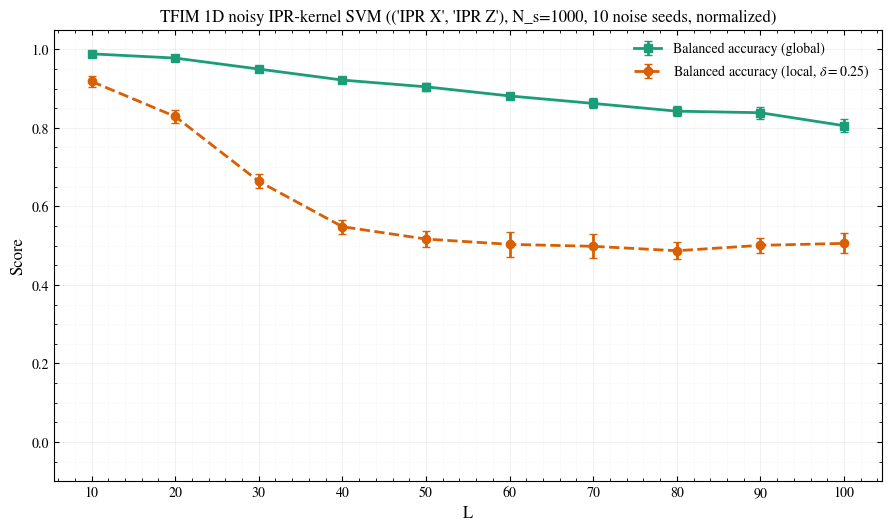

In [4]:
fig, ax, noisy_results = run_noisy_iprkernel_svm_experiment(
    dataset="tfim1d",
    L_values=L_VALUES_TFIM1D,
    N_s=1000,
    noise_seeds=list(range(10)),
    clip_eps=None,
    test_frac=0.10,
    local_delta=0.25,
    n_splits=1,
    rng_seed=12345,
    use_normalized_kernel=True,
    C=1.0,
    make_plot=True,
    print_report=True,
)

noisy_svm_score_table(noisy_results)

## `N_s` sweep

This cell evaluates several shot counts. The sweep returns a plot, a summary table, and the full result dictionary for each `N_s`.


,L,N_s,global_mean_pm_std,local_mean_pm_std,n_noise_seeds,n_splits_per_noise_seed,kernel_normalized
0,10,200,0.976250 +/- 0.005683,0.840750 +/- 0.011550,10,1,True
1,20,200,0.961000 +/- 0.006258,0.710250 +/- 0.022125,10,1,True
2,30,200,0.926750 +/- 0.009934,0.575000 +/- 0.016541,10,1,True
3,40,200,0.897250 +/- 0.010100,0.515750 +/- 0.019259,10,1,True
4,50,200,0.873250 +/- 0.010610,0.504500 +/- 0.014376,10,1,True
5,60,200,0.845500 +/- 0.016107,0.501750 +/- 0.040809,10,1,True
6,70,200,0.828250 +/- 0.012805,0.499500 +/- 0.026002,10,1,True
7,80,200,0.804250 +/- 0.013020,0.492750 +/- 0.026179,10,1,True
8,90,200,0.794000 +/- 0.015147,0.501250 +/- 0.025773,10,1,True
9,100,200,0.764750 +/- 0.015341,0.503500 +/- 0.023985,10,1,True


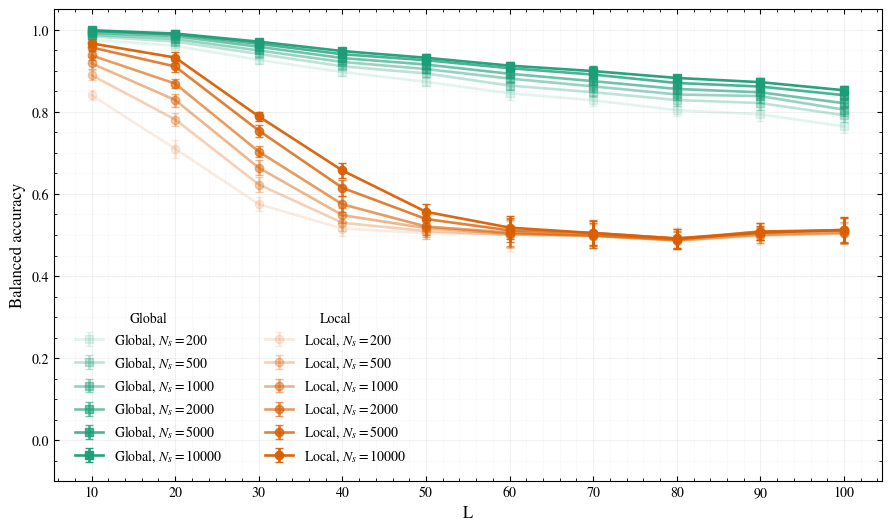

In [5]:
fig, ax, sweep_table, sweep_results = run_noisy_iprkernel_svm_ns_sweep(
    dataset="tfim1d",
    N_s_values=[200, 500, 1000, 2000, 5000, 10000],
    L_values=L_VALUES_TFIM1D,
    noise_seeds=list(range(10)),
    test_frac=0.10,
    local_delta=0.25,
    n_splits=1,
    rng_seed=12345,
    use_normalized_kernel=True,
    C=1.0,
    show_plot_title=False,
    make_plot=True,
)

sweep_table[
    [
        "L",
        "N_s",
        "global_mean_pm_std",
        "local_mean_pm_std",
        "n_noise_seeds",
        "n_splits_per_noise_seed",
        "kernel_normalized",
    ]
]